# Chapitre 8 - Cours 2 : l'algorithme EM et l'échantillonneur de Gibbs

Ce notebook couvre les sections 8.5 et 8.6 du livre :

1. le **mélange de deux gaussiennes** sur les 20 données fictives du tableau 8.1 ;
2. l'**algorithme EM** (*Expectation-Maximization*) pour ce mélange (algorithme 8.1,
   figures 8.5 et 8.6, tableau 8.2) ;
3. pourquoi EM fonctionne **en général** (algorithme 8.2, inégalité de Jensen) et sa
   lecture comme une double maximisation ;
4. les méthodes de **Monte-Carlo par chaînes de Markov** (MCMC) et l'**échantillonneur
   de Gibbs**, cousin « aléatoire » d'EM (algorithmes 8.3 et 8.4, figure 8.8).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch08_inference as inf
set_style()
rng = np.random.RandomState(0)

## 1. Les données et le modèle de mélange

Le tableau 8.1 du livre contient 20 nombres fictifs. Leur histogramme (figure 8.5,
panneau de gauche) présente **deux bosses** : une seule loi normale serait inadaptée.

In [2]:
y = np.sort(inf.MIXTURE_DATA)
N = len(y)
print(y)

[-0.39  0.06  0.12  0.48  0.94  1.01  1.67  1.68  1.76  1.8   2.44  3.25
  3.72  4.12  4.28  4.6   4.92  5.28  5.53  6.22]


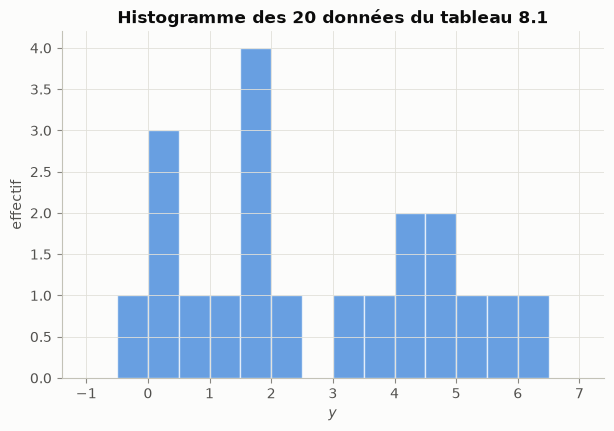

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(y, bins=np.arange(-1, 7.5, 0.5), color=BLUE, alpha=0.7, edgecolor="white")
ax.set(title="Histogramme des 20 données du tableau 8.1", xlabel="$y$", ylabel="effectif")
plt.show()

### Mélange de deux lois normales

On suppose que chaque observation provient de l'un de deux « régimes » :

$$Y_1 \sim N(\mu_1, \sigma_1^2), \qquad Y_2 \sim N(\mu_2, \sigma_2^2), \qquad
Y = (1 - \Delta)\,Y_1 + \Delta\,Y_2, \qquad \text{(éq. (8.36))}$$

où $\Delta \in \{0, 1\}$ est une variable de Bernoulli indépendante, avec
$\Pr(\Delta = 1) = \pi$. Autrement dit : on tire d'abord $\Delta$ (« pile ou face
biaisé »), puis on renvoie $Y_1$ si $\Delta = 0$ et $Y_2$ si $\Delta = 1$.

Notons $\phi_\theta$ la densité de $N(\mu, \sigma^2)$, $\theta = (\mu, \sigma^2)$. Par la
formule des probabilités totales (on conditionne par $\Delta$) :

$$g_Y(y) = (1 - \pi)\,\phi_{\theta_1}(y) + \pi\,\phi_{\theta_2}(y). \qquad
\text{(éq. (8.37))}$$

Illustrons le mécanisme génératif : on simule 2000 valeurs avec des paramètres proches
de ceux que nous estimerons, en coloriant selon la valeur (cachée) de $\Delta$.

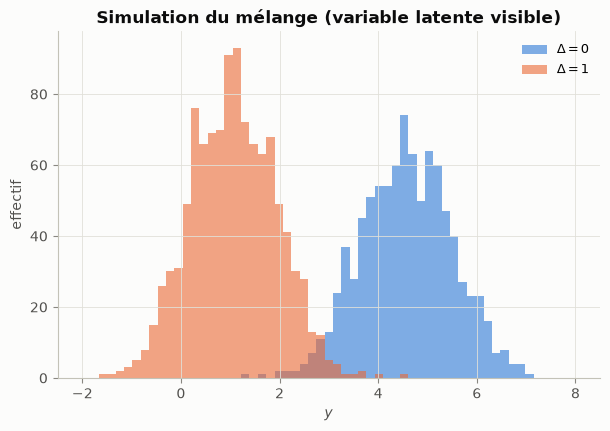

In [4]:
theta_demo = (4.6, 0.8, 1.1, 0.8, 0.55)        # (mu1, var1, mu2, var2, pi)
D = rng.rand(2000) < theta_demo[4]
Ysim = np.where(D, theta_demo[2] + np.sqrt(theta_demo[3]) * rng.randn(2000),
                theta_demo[0] + np.sqrt(theta_demo[1]) * rng.randn(2000))
tt = np.linspace(-2, 8, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.linspace(-2, 8, 60)
ax.hist(Ysim[~D], bins=bins, density=False, color=BLUE, alpha=0.6, label=r"$\Delta = 0$")
ax.hist(Ysim[D], bins=bins, density=False, color=ORANGE, alpha=0.6, label=r"$\Delta = 1$")
ax.set(title="Simulation du mélange (variable latente visible)", xlabel="$y$",
       ylabel="effectif")
ax.legend()
plt.show()

### La log-vraisemblance

Les paramètres sont $\theta = (\pi, \theta_1, \theta_2) = (\pi, \mu_1, \sigma_1^2, \mu_2,
\sigma_2^2)$ (éq. (8.38)) et la log-vraisemblance des $N$ observations vaut

$$\ell(\theta; Z) = \sum_{i=1}^N \log\big[(1 - \pi)\phi_{\theta_1}(y_i) +
\pi\,\phi_{\theta_2}(y_i)\big]. \qquad \text{(éq. (8.39))}$$

La **somme à l'intérieur du logarithme** empêche d'obtenir des formules explicites :
les équations $\partial\ell/\partial\theta = 0$ couplent tous les paramètres.

### L'astuce : les variables latentes

Si l'on connaissait les $\Delta_i$ (variables **latentes**, c'est-à-dire non observées),
la log-vraisemblance « complète » serait

$$\ell_0(\theta; Z, \Delta) = \sum_{i=1}^N \big[(1-\Delta_i)\log\phi_{\theta_1}(y_i) +
\Delta_i\log\phi_{\theta_2}(y_i)\big] + \sum_{i=1}^N\big[(1-\Delta_i)\log(1-\pi) +
\Delta_i\log\pi\big]. \qquad \text{(éq. (8.40))}$$

Elle se sépare en trois morceaux indépendants : $\hat\mu_1, \hat\sigma_1^2$ seraient la
moyenne et la variance empiriques des points où $\Delta_i = 0$, de même pour
$\hat\mu_2, \hat\sigma_2^2$, et $\hat\pi$ la proportion de $\Delta_i = 1$.

### Les responsabilités

Ne connaissant pas les $\Delta_i$, on les remplace par leur espérance conditionnelle

$$\gamma_i(\theta) = E(\Delta_i\mid\theta, Z) = \Pr(\Delta_i = 1\mid\theta, Z),
\qquad \text{(éq. (8.41))}$$

appelée **responsabilité** de la composante 2 pour l'observation $i$. Par la formule de
Bayes, $\Pr(\Delta_i = 1\mid y_i) = \frac{\Pr(\Delta_i = 1)\,g(y_i\mid\Delta_i = 1)}
{g_Y(y_i)}$, soit

$$\hat\gamma_i = \frac{\hat\pi\,\phi_{\hat\theta_2}(y_i)}{(1-\hat\pi)\phi_{\hat\theta_1}(y_i)
+ \hat\pi\,\phi_{\hat\theta_2}(y_i)}. \qquad \text{(éq. (8.42))}$$

## 2. L'algorithme EM pour le mélange (algorithme 8.1)

1. **Initialisation** : $\hat\mu_1, \hat\mu_2$ = deux observations tirées au hasard,
   $\hat\sigma_1^2 = \hat\sigma_2^2$ = variance empirique globale, $\hat\pi = 0{,}5$.
2. **Étape E** (*Expectation*) : calculer les responsabilités $\hat\gamma_i$ par (8.42)
   - une affectation « douce » de chaque point aux deux composantes.
3. **Étape M** (*Maximization*) : moyennes et variances **pondérées**
   $$\hat\mu_1 = \frac{\sum_i (1-\hat\gamma_i)y_i}{\sum_i(1-\hat\gamma_i)}, \quad
   \hat\sigma_1^2 = \frac{\sum_i(1-\hat\gamma_i)(y_i-\hat\mu_1)^2}{\sum_i(1-\hat\gamma_i)},
   \quad \hat\mu_2 = \frac{\sum_i\hat\gamma_iy_i}{\sum_i\hat\gamma_i}, \quad
   \hat\sigma_2^2 = \frac{\sum_i\hat\gamma_i(y_i-\hat\mu_2)^2}{\sum_i\hat\gamma_i},$$
   et $\hat\pi = \frac1N\sum_i\hat\gamma_i$.
4. Répéter 2 et 3 jusqu'à convergence.

L'implémentation se trouve dans `esl.ch08_inference.em_mixture`.

Comme dans le livre, on lance EM depuis plusieurs initialisations et on garde la
meilleure log-vraisemblance.

In [5]:
runs = []
for s in range(10):
    i, j = rng.choice(N, 2, replace=False)
    r = inf.em_mixture(y, (y[i], y.var(), y[j], y.var(), 0.5), n_iter=200, tol=1e-10)
    runs.append(r)
    print("départ mu=(%5.2f, %5.2f) -> mu1=%.3f mu2=%.3f pi=%.3f   loglik=%.4f"
          % (y[i], y[j], r["theta"][0], r["theta"][2], r["theta"][4], r["loglik"][-1]))

départ mu=( 1.67,  4.60) -> mu1=1.083 mu2=4.656 pi=0.445   loglik=-38.9134
départ mu=( 5.53,  4.92) -> mu1=4.656 mu2=1.083 pi=0.555   loglik=-38.9134
départ mu=( 1.68,  3.25) -> mu1=1.083 mu2=4.656 pi=0.445   loglik=-38.9134
départ mu=( 0.12,  1.01) -> mu1=1.083 mu2=4.656 pi=0.445   loglik=-38.9134
départ mu=( 2.44,  0.12) -> mu1=4.656 mu2=1.083 pi=0.555   loglik=-38.9134
départ mu=( 0.94,  3.72) -> mu1=1.083 mu2=4.656 pi=0.445   loglik=-38.9134
départ mu=( 1.80,  1.01) -> mu1=4.656 mu2=1.083 pi=0.555   loglik=-38.9134
départ mu=( 2.44,  6.22) -> mu1=1.083 mu2=4.656 pi=0.445   loglik=-38.9134
départ mu=( 0.48,  3.72) -> mu1=1.083 mu2=4.656 pi=0.445   loglik=-38.9134
départ mu=( 3.25,  0.48) -> mu1=4.656 mu2=1.083 pi=0.555   loglik=-38.9134


Tous les départs mènent à la même solution, à une **permutation des étiquettes** près
(échanger les composantes 1 et 2 et remplacer $\pi$ par $1 - \pi$ ne change pas le
modèle). Retenons l'étiquetage du livre : composante 1 à droite, composante 2 à gauche.

In [6]:
best = max(runs, key=lambda r: r["loglik"][-1])
mu1, v1, mu2, v2, pi = best["theta"]
if mu1 < mu2:                                       # étiquetage du livre
    mu1, v1, mu2, v2, pi = mu2, v2, mu1, v1, 1 - pi
theta_hat = (mu1, v1, mu2, v2, pi)
print("mu1 = %.2f  sigma1^2 = %.2f" % (mu1, v1))
print("mu2 = %.2f  sigma2^2 = %.2f" % (mu2, v2))
print("pi  = %.3f" % pi)

mu1 = 4.66  sigma1^2 = 0.82
mu2 = 1.08  sigma2^2 = 0.81
pi  = 0.555


Le livre rapporte $\hat\mu_1 = 4{,}62$, $\hat\sigma_1^2 = 0{,}87$, $\hat\mu_2 = 1{,}06$,
$\hat\sigma_2^2 = 0{,}77$, $\hat\pi = 0{,}546$. Nos valeurs, obtenues à convergence
complète, en sont très proches ; la petite différence vient vraisemblablement de l'arrêt
du livre après une vingtaine d'itérations.

### Progression de l'algorithme (tableau 8.2 et figure 8.6)

Pour suivre une trajectoire semblable à celle du livre, partons de
$\hat\mu_1 = 4{,}5$, $\hat\mu_2 = 1$, variances égales à la variance globale et
$\hat\pi = 0{,}5$.

In [7]:
traj = inf.em_mixture(y, (4.5, y.var(), 1.0, y.var(), 0.5), n_iter=20)
print("Itération   pi_hat    log-vraisemblance")
for it in [1, 5, 10, 15, 20]:
    print("%9d   %.3f    %.3f" % (it, traj["thetas"][it, 4], traj["loglik"][it]))

Itération   pi_hat    log-vraisemblance
        1   0.518    -41.378
        5   0.524    -39.113
       10   0.550    -38.916
       15   0.554    -38.913
       20   0.555    -38.913


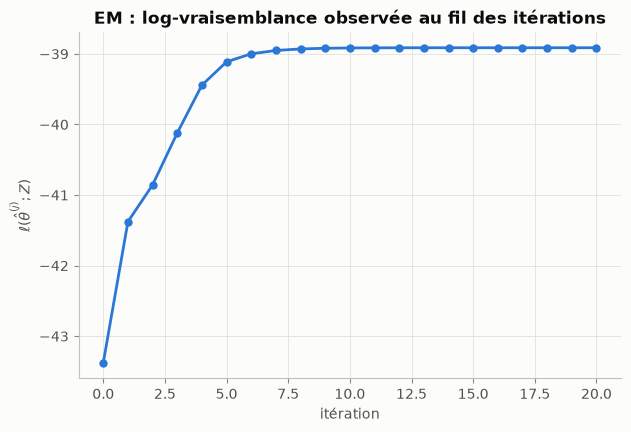

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(0, 21), traj["loglik"], color=BLUE, marker="o")
ax.set(title="EM : log-vraisemblance observée au fil des itérations",
       xlabel="itération", ylabel=r"$\ell(\hat\theta^{(j)}; Z)$")
plt.show()

La log-vraisemblance **croît à chaque itération** : nous le démontrons plus bas.

### Densité ajustée et responsabilités (figure 8.5, droite)

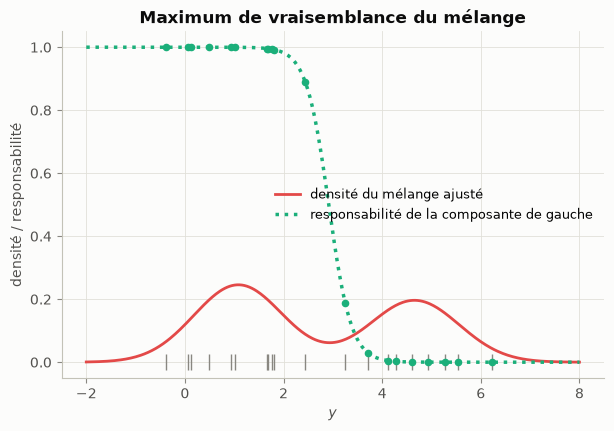

In [9]:
dens = (1 - pi) * inf.normal_pdf(tt, mu1, v1) + pi * inf.normal_pdf(tt, mu2, v2)
resp_left = inf.responsibilities(tt, theta_hat)       # composante 2 = composante de gauche
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(tt, dens, color=COLORS[7], label="densité du mélange ajusté")
ax.plot(tt, resp_left, color=COLORS[2], ls=":", lw=2.5,
        label="responsabilité de la composante de gauche")
ax.scatter(y, inf.responsibilities(y, theta_hat), color=COLORS[2], s=20, zorder=3)
ax.plot(y, np.zeros(N), "|", color=GRAY, ms=12)
ax.set(title="Maximum de vraisemblance du mélange", xlabel="$y$",
       ylabel="densité / responsabilité")
ax.legend(loc="center right")
plt.show()

### Un piège : la vraisemblance n'est pas bornée

Le « vrai » maximum de $\ell$ est infini : posons $\mu_1 = y_1$ et faisons tendre
$\sigma_1^2 \to 0$. Le terme $\log[(1-\pi)\phi_{\theta_1}(y_1) + \dots]$ tend vers
$+\infty$, tandis que les autres termes restent bornés grâce à la seconde composante.
On cherche donc un **bon maximum local** avec $\hat\sigma_1^2, \hat\sigma_2^2 > 0$.

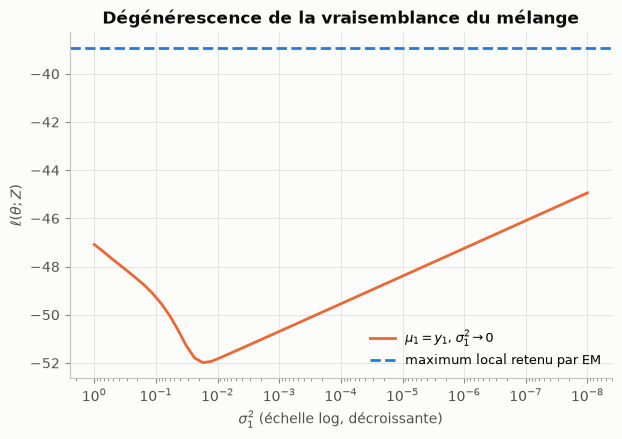

In [10]:
vs = np.logspace(-8, 0, 60)
ll_spike = [inf.mixture_loglik(y, (y[0], v, y.mean(), y.var(), 0.5)) for v in vs]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(vs, ll_spike, color=ORANGE, label=r"$\mu_1 = y_1$, $\sigma_1^2 \to 0$")
ax.axhline(best["loglik"][-1], color=BLUE, ls="--", label="maximum local retenu par EM")
ax.invert_xaxis()
ax.set(title="Dégénérescence de la vraisemblance du mélange",
       xlabel=r"$\sigma_1^2$ (échelle log, décroissante)", ylabel=r"$\ell(\theta; Z)$")
ax.legend()
plt.show()

## 3. L'algorithme EM en général (section 8.5.2)

Cadre : données observées $Z$, de log-vraisemblance $\ell(\theta; Z)$ difficile à
maximiser ; données **latentes** (ou manquantes) $Z^m$ ; données **complètes**
$T = (Z, Z^m)$ de log-vraisemblance $\ell_0(\theta; T)$ facile à maximiser. Pour le
mélange, $(Z, Z^m) = (y, \Delta)$ et $\ell_0$ est (8.40). Ajouter des données fictives
pour simplifier le problème s'appelle l'**augmentation de données**.

**Algorithme 8.2.**
1. Choisir $\hat\theta^{(0)}$.
2. **Étape E** : calculer, comme fonction de l'argument muet $\theta'$,
   $$Q(\theta', \hat\theta^{(j)}) = E\big(\ell_0(\theta'; T)\mid Z, \hat\theta^{(j)}\big).
   \qquad \text{(éq. (8.43))}$$
3. **Étape M** : $\hat\theta^{(j+1)} = \arg\max_{\theta'} Q(\theta', \hat\theta^{(j)})$.
4. Itérer jusqu'à convergence.

Pour le mélange, $\ell_0$ est affine en les $\Delta_i$, donc $Q$ s'obtient en remplaçant
$\Delta_i$ par $\hat\gamma_i$ dans (8.40) ; l'étape M donne les moyennes et variances
pondérées.

### Pourquoi EM fait croître la vraisemblance

Par définition de la probabilité conditionnelle,
$\Pr(Z^m\mid Z, \theta') = \Pr(Z^m, Z\mid\theta')/\Pr(Z\mid\theta')$ (éq. (8.44)), donc
$\Pr(Z\mid\theta') = \Pr(T\mid\theta')/\Pr(Z^m\mid Z, \theta')$ (éq. (8.45)). En passant
au logarithme :

$$\ell(\theta'; Z) = \ell_0(\theta'; T) - \ell_1(\theta'; Z^m\mid Z),$$

où $\ell_1$ est la log-densité conditionnelle de $Z^m$ sachant $Z$. Le membre de gauche
ne dépend pas de $Z^m$ ; on prend l'espérance conditionnelle sous la loi de
$T\mid Z$ de paramètre $\theta$ :

$$\ell(\theta'; Z) = \underbrace{E[\ell_0(\theta'; T)\mid Z, \theta]}_{Q(\theta', \theta)}
- \underbrace{E[\ell_1(\theta'; Z^m\mid Z)\mid Z, \theta]}_{R(\theta', \theta)}.
\qquad \text{(éq. (8.46))}$$

### L'inégalité de Jensen

> **Rappel.** Si $\varphi$ est convexe, $E[\varphi(X)] \ge \varphi(E[X])$ (inégalité de
> Jensen). Avec $\varphi = -\log$ (convexe) : $E[\log X] \le \log E[X]$ pour $X > 0$.

$R(\theta^*, \theta)$ est l'espérance, sous la densité indexée par $\theta$, du log
d'une densité indexée par $\theta^*$. Notons $q$ et $r$ ces deux densités. Alors

$$R(\theta^*, \theta) - R(\theta, \theta) = E_q\Big[\log\frac{r}{q}\Big] \le
\log E_q\Big[\frac rq\Big] = \log\int r = 0,$$

donc $R(\cdot, \theta)$ est maximale en $\theta^* = \theta$ (exercice 8.1). Si $\theta'$
maximise $Q(\cdot, \theta)$ :

$$\ell(\theta'; Z) - \ell(\theta; Z) = \underbrace{[Q(\theta', \theta) - Q(\theta, \theta)]}
_{\ge 0} - \underbrace{[R(\theta', \theta) - R(\theta, \theta)]}_{\le 0} \ge 0.
\qquad \text{(éq. (8.47))}$$

> **À retenir.** Une itération EM ne fait **jamais décroître** la log-vraisemblance. Il
> suffit même d'augmenter $Q$ sans la maximiser : c'est l'algorithme EM **généralisé**
> (GEM).

Vérifions numériquement la décomposition $\ell = Q - R$ et les deux inégalités sur la
trajectoire EM précédente.

In [11]:
def R_mixture(theta_new, theta_old):
    """R(theta', theta) = E[log Pr(Delta | y, theta') | y, theta] pour le mélange."""
    g_old = inf.responsibilities(y, theta_old)
    g_new = inf.responsibilities(y, theta_new)
    return np.sum(g_old * np.log(g_new) + (1 - g_old) * np.log(1 - g_new))

print(" j   l(theta_j+1)-l(theta_j)   dQ >= 0     -dR >= 0")
for j in range(0, 10):
    th0, th1 = traj["thetas"][j], traj["thetas"][j + 1]
    l0, l1 = inf.mixture_loglik(y, th0), inf.mixture_loglik(y, th1)
    dQ = inf.mixture_Q(y, th1, th0) - inf.mixture_Q(y, th0, th0)
    dR = R_mixture(th1, th0) - R_mixture(th0, th0)
    assert abs((l1 - l0) - (dQ - dR)) < 1e-9
    print("%2d   %22.5f   %8.5f   %9.5f" % (j, l1 - l0, dQ, -dR))

 j   l(theta_j+1)-l(theta_j)   dQ >= 0     -dR >= 0
 0                  1.99856    1.81791     0.18065
 1                  0.52099    0.24238     0.27861
 2                  0.73576    0.37199     0.36377
 3                  0.67819    0.39611     0.28208
 4                  0.33005    0.21518     0.11487
 5                  0.11380    0.07264     0.04116
 6                  0.04728    0.02868     0.01859
 7                  0.02170    0.01310     0.00860
 8                  0.00962    0.00583     0.00379
 9                  0.00413    0.00250     0.00163


## 4. EM comme double maximisation (section 8.5.3)

Considérons, pour toute loi $\tilde P$ sur les données latentes,

$$F(\theta', \tilde P) = E_{\tilde P}[\ell_0(\theta'; T)] - E_{\tilde P}[\log\tilde P(Z^m)].
\qquad \text{(éq. (8.48))}$$

Le second terme est l'**entropie** de $\tilde P$. On montre (exercice 8.2) que, à
$\theta'$ fixé, $F$ est maximale pour $\tilde P(Z^m) = \Pr(Z^m\mid Z, \theta')$
(éq. (8.49)), et qu'alors $F(\theta', \tilde P) = \ell(\theta'; Z)$. EM est donc une
**montée par coordonnées** sur $F$ :

* étape E : maximiser $F$ en $\tilde P$ (à $\theta'$ fixé) ;
* étape M : maximiser $F$ en $\theta'$ (à $\tilde P$ fixé), ce qui revient à maximiser
  $E_{\tilde P}[\ell_0(\theta'; T)]$, le second terme ne dépendant pas de $\theta'$.

Pour le mélange, une loi $\tilde P$ « produit » est décrite par des probabilités
$\gamma_i = \tilde P(\Delta_i = 1)$ ; on peut alors écrire $F$ explicitement.

In [12]:
def F_mixture(theta, gam):
    mu1, v1, mu2, v2, pi = theta
    g = np.clip(gam, 1e-12, 1 - 1e-12)
    e0 = np.sum((1 - g) * (np.log(1 - pi) + np.log(inf.normal_pdf(y, mu1, v1)))
                + g * (np.log(pi) + np.log(inf.normal_pdf(y, mu2, v2))))
    ent = -np.sum(g * np.log(g) + (1 - g) * np.log(1 - g))
    return e0 + ent

print("F(theta, responsabilités) = %.6f" % F_mixture(theta_hat, inf.responsibilities(y, theta_hat)))
print("l(theta)                  = %.6f" % inf.mixture_loglik(y, theta_hat))
print("F(theta, gamma aléatoires) max sur 1000 tirages = %.6f"
      % max(F_mixture(theta_hat, rng.rand(N)) for _ in range(1000)))

F(theta, responsabilités) = -38.913372
l(theta)                  = -38.913372
F(theta, gamma aléatoires) max sur 1000 tirages = -74.180530


Visualisons cette double maximisation dans un cas réduit, analogue à la figure 8.7 :
seul $\mu_2$ est libre (les autres paramètres sont fixés à leur estimation), et la loi
latente est restreinte à la famille à un paramètre
$\gamma_i(s) = \Pr(\Delta_i = 1\mid y_i, \mu_2 = s)$. On trace les lignes de niveau de
$F(\mu_2, s)$ et la trajectoire EM, qui alterne déplacements horizontaux (étape E) et
verticaux (étape M).

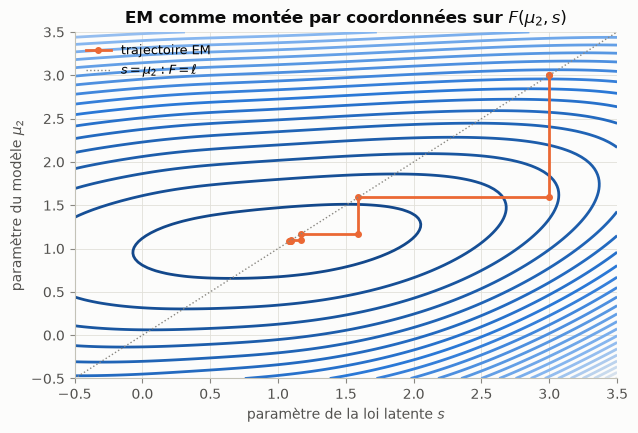

In [13]:
def theta_mu2(m):
    return (mu1, v1, m, v2, pi)

grid = np.linspace(-0.5, 3.5, 120)
Fgrid = np.array([[F_mixture(theta_mu2(m), inf.responsibilities(y, theta_mu2(s)))
                   for s in grid] for m in grid])
path_s, path_m = [], []
m = s = 3.0
for _ in range(6):
    path_s.append(s); path_m.append(m)
    s = m                                            # étape E : s <- mu2 courant
    path_s.append(s); path_m.append(m)
    g = inf.responsibilities(y, theta_mu2(s))
    m = np.sum(g * y) / np.sum(g)                    # étape M sur mu2
fig, ax = plt.subplots(figsize=(7, 4.5))
cs = ax.contour(grid, grid, Fgrid, levels=25, cmap=SEQ)
ax.plot(path_s, path_m, color=ORANGE, marker="o", ms=4, label="trajectoire EM")
ax.plot(grid, grid, color=GRAY, ls=":", lw=1, label=r"$s = \mu_2$ : $F = \ell$")
ax.set(title=r"EM comme montée par coordonnées sur $F(\mu_2, s)$",
       xlabel=r"paramètre de la loi latente $s$", ylabel=r"paramètre du modèle $\mu_2$")
ax.legend(loc="upper left")
plt.show()